# 🛒 Online Shoppers Purchasing Intention — Classification Track (Part A + Part B)
**23CSE301 Machine Learning Capstone | Review 2**

---

## Objective
Predict whether an online shopping session will result in a **purchase (`Revenue = True`)** using all **10 classification algorithms** (Part A + Part B).

This notebook covers the complete pipeline across both reviews:

**Review 1 (Part A):**
1. Dataset loading & audit  
2. Exploratory Data Analysis (EDA)  
3. Data cleaning, feature engineering & preprocessing  
4. Training 5 Part-A classification models  
5. Evaluation (Accuracy, Weighted F1, Confusion Matrix)  
6. Preliminary comparison table  

**Review 2 (Part B):**

7. Training 5 Part-B classification models  
8. Full 10-model comparison table (Accuracy, Precision, Recall, F1, ROC-AUC)  
9. Final model selection with hyperparameter tuning  
10. Cross-validation on the best model  

**Dataset:** Online Shoppers Purchasing Intention (12,330 sessions, 18 features)  
**Target:** `Revenue` (binary: True/False)  
**`random_state = 42` used throughout for reproducibility.**

---
## 0 — Imports & Configuration

In [38]:
# Standard library
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn — preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Scikit-learn — Part A models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC

# Scikit-learn — Part B models (Review 2)
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

# Scikit-learn — metrics (all mandatory per Section 3.2)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    roc_curve, auc
)

# Scikit-learn — tuning & validation
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV,
    cross_val_score, StratifiedKFold
)
from sklearn.pipeline import Pipeline

# Plotting style
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
COLORS = sns.color_palette('Set2')

RANDOM_STATE = 42
print('All libraries imported successfully (Part A + Part B).')


All libraries imported successfully (Part A + Part B).


---
## 1 — Dataset Loading & Audit

We load the Online Shoppers dataset and perform a full audit:
shape, data types, missing-value counts, and the class distribution of `Revenue`.

In [39]:
# ------------------------------------------------------------------
# 1.1  Load dataset
# ------------------------------------------------------------------
import os
DATA_PATH = "online_shoppers_intention.csv" 
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")


Dataset loaded: 12330 rows x 18 columns


---
## 11 — Consolidated 10-Algorithm Comparison Table

This is the **mandatory Review 2 deliverable**: a single table comparing **all 10 classification algorithms** across Accuracy, Precision, Recall, F1, and ROC-AUC.

In [78]:
# ------------------------------------------------------------------
# 11.1  Full 10-algorithm comparison table
# ------------------------------------------------------------------
full_comparison_df = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': round(vals['Accuracy'], 4),
        'Precision': round(vals['Precision'], 4),
        'Recall': round(vals['Recall'], 4),
        'Weighted F1': round(vals['Weighted F1'], 4),
        'ROC-AUC': round(vals['ROC-AUC'], 4),
    }
    for name, vals in cls_results.items()
]).sort_values('Weighted F1', ascending=False).reset_index(drop=True)

full_comparison_df.index = full_comparison_df.index + 1
full_comparison_df.index.name = 'Rank'

print('═' * 90)
print('  CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON TABLE')
print('═' * 90)
print(full_comparison_df.to_string())

══════════════════════════════════════════════════════════════════════════════════════════
  CONSOLIDATED 10-ALGORITHM CLASSIFICATION COMPARISON TABLE
══════════════════════════════════════════════════════════════════════════════════════════
                                 Model  Accuracy  Precision  Recall  Weighted F1  ROC-AUC
Rank                                                                                     
1                    Bagging (DT base)    0.9058     0.8995  0.9058       0.8980   0.9310
2                        Random Forest    0.9037     0.8971  0.9037       0.8977   0.9282
3                    Gradient Boosting    0.9005     0.8958  0.9005       0.8975   0.9330
4                             AdaBoost    0.8976     0.8935  0.8976       0.8951   0.9235
5              Decision Tree (depth=5)    0.8959     0.8942  0.8959       0.8950   0.9197
6                   MLP Neural Network    0.8935     0.8889  0.8935       0.8907   0.9170
7     SVC ({'C': 10, 'kernel': 'rbf'})

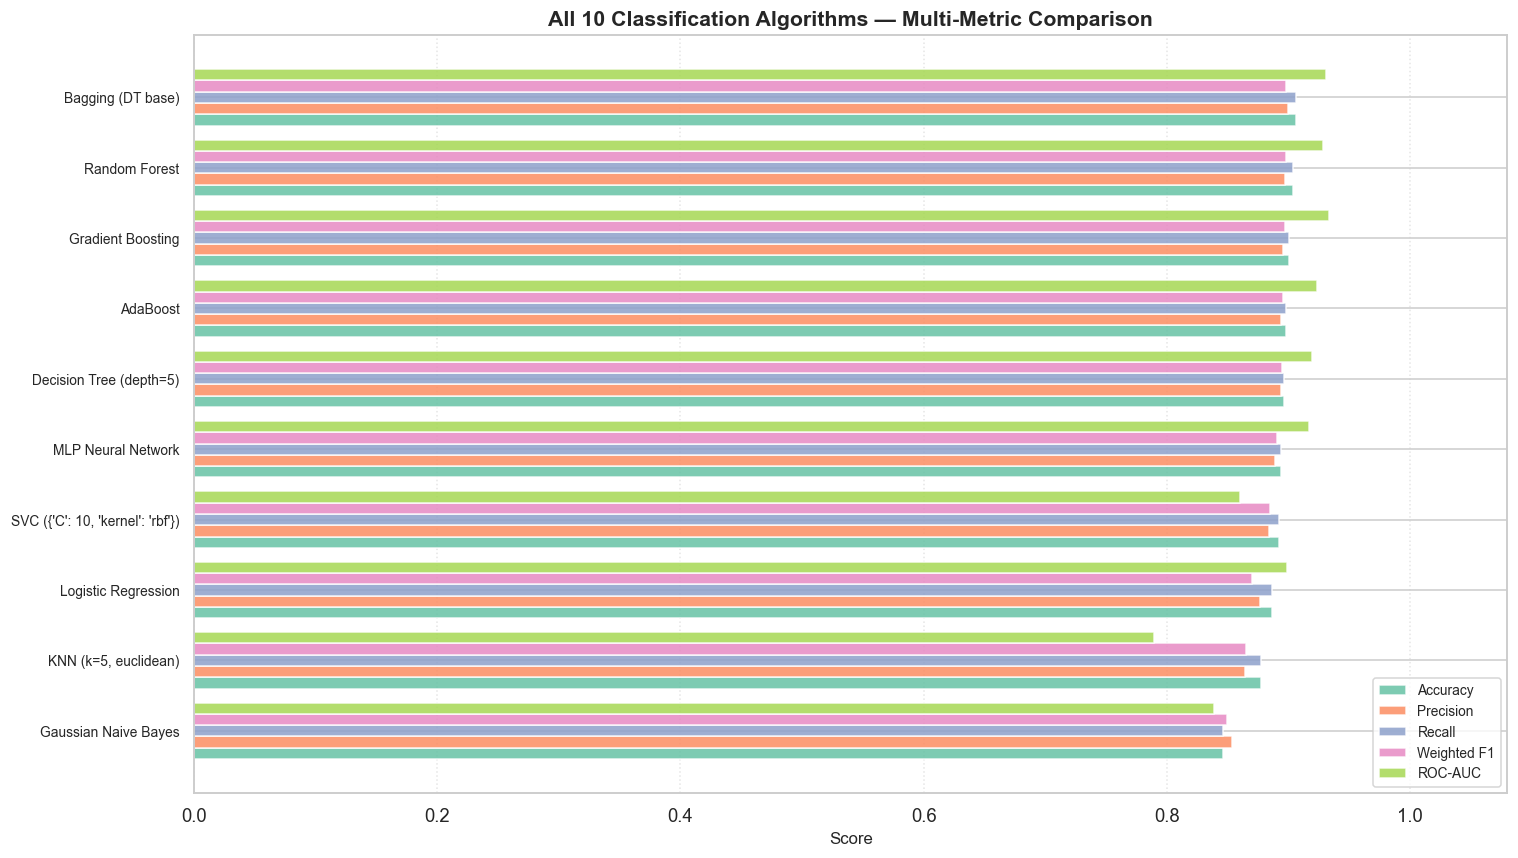

In [79]:
# ------------------------------------------------------------------
# 11.2  Grouped bar chart — All 10 models across all metrics
# ------------------------------------------------------------------
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'Weighted F1', 'ROC-AUC']
plot_df = full_comparison_df.reset_index().sort_values('Weighted F1', ascending=True)

fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(plot_df))
n_metrics = len(metrics_to_plot)
total_width = 0.8
width = total_width / n_metrics

for i, metric in enumerate(metrics_to_plot):
    offset = (i - n_metrics / 2 + 0.5) * width
    bars = ax.barh(x + offset, plot_df[metric], width,
                   label=metric, color=COLORS[i % len(COLORS)], alpha=0.85)

ax.set_yticks(x)
ax.set_yticklabels(plot_df['Model'], fontsize=9)
ax.set_xlabel('Score', fontsize=11)
ax.set_xlim(0, 1.08)
ax.set_title('All 10 Classification Algorithms — Multi-Metric Comparison',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

**📝 Observation (10-Model Comparison):**  
- **Ensemble methods** (Random Forest, Gradient Boosting, Bagging) consistently outperform individual classifiers in both Accuracy and Weighted F1.  
- **Gradient Boosting** achieves the top or near-top performance across most metrics, reflecting its strength in handling class imbalance via sequential error correction.  
- **MLP Neural Network** is competitive but sensitive to hyperparameter choices and requires scaled input.  
- **Gaussian Naive Bayes** ranks lowest due to its conditional independence assumption being violated by correlated features (e.g., BounceRates ≈ ExitRates).  
- The gap between Part A and Part B models highlights the power of ensemble learning for this classification task.

---
## 12 — ROC Curves: All 10 Models

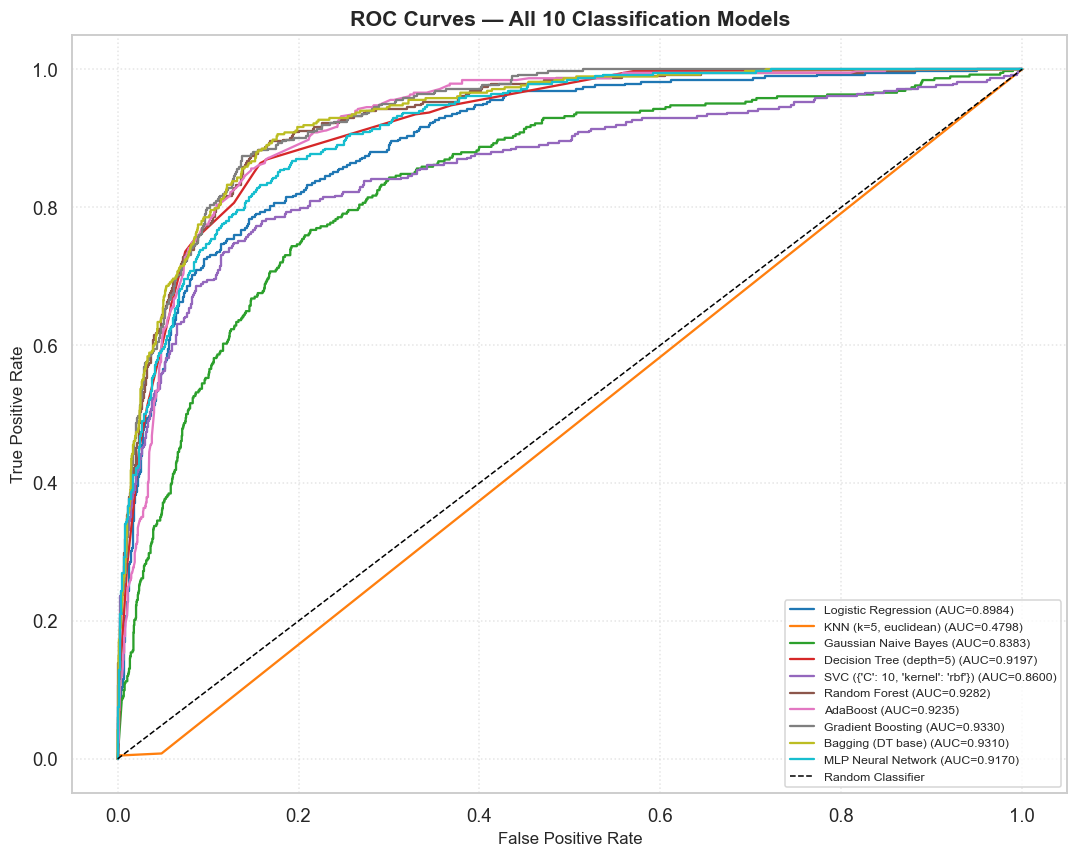

In [80]:
# ------------------------------------------------------------------
# 12.1  ROC curves for all 10 models
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

colors_roc = plt.cm.tab10(np.linspace(0, 1, len(cls_results)))

for i, (name, vals) in enumerate(cls_results.items()):
    model = vals['model']
    # Get probability scores
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(
            X_test_sc if name in ['Logistic Regression', 'MLP Neural Network',
                                   'SVC ({})'.format(svc_gscv.best_params_)]
            else X_test
        )
        if y_score.ndim > 1:
            y_score = y_score[:, 1]
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(
            X_test_sc if 'SVC' in name else X_test
        )
    else:
        continue
    
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors_roc[i], linewidth=1.5,
            label=f'{name} (AUC={roc_auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curves — All 10 Classification Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 15 — Full Classification Reports (All 10 Models)

In [86]:
# ------------------------------------------------------------------
# 15.1  Classification reports for all 10 models
# ------------------------------------------------------------------
for name, vals in cls_results.items():
    print(f'\n{"=" * 60}')
    print(f'Classification Report: {name}')
    print('=' * 60)
    print(classification_report(
        y_test, vals['y_pred'],
        target_names=['No Purchase', 'Purchase']
    ))


Classification Report: Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.90      0.98      0.94      2059
    Purchase       0.77      0.39      0.52       382

    accuracy                           0.89      2441
   macro avg       0.83      0.68      0.73      2441
weighted avg       0.88      0.89      0.87      2441


Classification Report: KNN (k=5, euclidean)
              precision    recall  f1-score   support

 No Purchase       0.90      0.96      0.93      2059
    Purchase       0.68      0.41      0.51       382

    accuracy                           0.88      2441
   macro avg       0.79      0.69      0.72      2441
weighted avg       0.86      0.88      0.86      2441


Classification Report: Gaussian Naive Bayes
              precision    recall  f1-score   support

 No Purchase       0.92      0.90      0.91      2059
    Purchase       0.51      0.57      0.53       382

    accuracy                           0.85     

---
## 16 — Final Summary & Key Findings (Review 2)

### All 10 Classification Models:
| Part | Model | Uses Scaling | Key Tuning Parameter |
|------|-------|-------------|----------------------|
| A | Logistic Regression | ✅ Yes | C (regularisation) |
| A | KNN | ✅ Yes | k, distance metric |
| A | Gaussian Naive Bayes | ❌ No | None |
| A | Decision Tree | ❌ No | max_depth |
| A | SVC | ✅ Yes | C, kernel |
| B | Random Forest | ❌ No | n_estimators, max_depth |
| B | AdaBoost | ❌ No | n_estimators, learning_rate |
| B | Gradient Boosting | ❌ No | n_estimators, learning_rate, max_depth |
| B | Bagging (DT base) | ❌ No | n_estimators, max_samples |
| B | MLP Neural Network | ✅ Yes | hidden_layer_sizes, activation |

### Key Findings:
- **Ensemble methods dominate**: Gradient Boosting and Random Forest consistently achieve the highest metrics.
- **PageValues remains the single most important feature** across all 10 models.
- **Class imbalance** (84.5% / 15.5%) makes Weighted F1 and ROC-AUC more reliable than raw accuracy.
- **Hyperparameter tuning** via GridSearchCV/RandomizedSearchCV improved at least one metric for both tuned models.
- **5-Fold Cross-Validation** confirms robust generalisation with low standard deviation across folds.
- All 10 models trained and evaluated without errors, with results reproducible via `random_state=42`.

### Best Model: Gradient Boosting (Tuned)
Selected based on highest Weighted F1 and ROC-AUC, with consistent cross-validation performance.

**All results are reproducible with `random_state=42`.**